# TP: Machine Learning

## TP1: Linear Regression (4h)  

Linear regression is a family of machine learning algorithms aiming at adjusting a linear model to an ensemble of data. The applications range from signal reconstruction to empirical description.

The given dataset was produced by the World Health Organization. It pooled the evolution of 20 features for 15 years and among numerous countries. One of the goals of this TP1 is to manipulate this dataset and try to predict the evolution of Life Expectancy through different variables.

**Objectives:**
- Use and setup an iPython environment
- Manipulate and visualize data
- Implement a simple linear regression
- Apply the aforementioned linear regression
- Compute a $R^2$ on the generated results
- Apply Ridge and Lasso regressions


To code this TP, you can use your own iPython environment, or chose to use the ENSEA's jupyter server available on https://io.ensea.fr

This TP has different **checkpoints**. Please call your teacher at the end of each checkpoint to validate your work. Any non validated work won't be taken into account in the notation


## STEP 1: Use and setup an iPython environment

iPython and Notebook environments are useful tools to quickly prototype and test machine learning solutions. However, they have limitations especially in RAM and disk access.

**TO DO 1.1**

Execute the following cells

In [27]:
a = 3
b = 4
c = a + b

In [28]:
c = c

In [29]:
print(c)

7


In [30]:
c

7

**QUESTION 1**

What is triggering the output display?


On utilise la fonction print() qui demande explicitement un affichage de la valeur c.

**TO DO 1.2**

Execute the following cells

In [ ]:
import shutil
import pkgutil

def show_acceptable_modules():
    
    line = '-' * 100
    print('{}\n{:^30}|{:^20}\n{}'.format(line, 'Module', 'Location', line))
    for entry in pkgutil.iter_modules():
        print('{:30}| {}'.format(entry[1], entry[0].path))

In [32]:
show_acceptable_modules()

import sys
print(sys.version)

----------------------------------------------------------------------------------------------------
            Module            |      Location      
----------------------------------------------------------------------------------------------------
_asyncio                      | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_bz2                          | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_ctypes                       | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_decimal                      | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_elementtree                  | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_hashlib                      | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_lzma                         | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_multiprocessing              | c:\Users\liamn\AppData\Local\Python\pythoncore-3.15-64\DLLs
_overlappe

**QUESTION 2**

What is displayed on the last output?
La fonction show_acceptable_modules permet d'afficher la liste entière des modules, paquets de l'environnement python ainsi que leur location respectif.

Which is the used Python version?
La verion utilisé est la 3.15. La fonction rajouter permet d'etre plus précis avec la version 3.15.2.

For this TP1, you will need:
- pandas
- matplotlib
- numpy
- sklearn

Are these packages installed in this environment?
Ces paquets sont bien installés dans notre environnement python.

**TO DO 1.3**

Execute the following cell

In [33]:
import pandas as pd
pd.__version__

'3.1.0'

**QUESTION 3**

How would you solve this error?

La bibliothèque pandas n'a pas été importer. On rajoute donc: "import pandas as pd".
La version de pandas est donc '3.1.0'.

## STEP 2: Data manipulation and visualization


**TO DO 2.1**

Execute the following cell

In [34]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("Life_Expectancy_Data.csv")
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 1649 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          1649 non-null   str    
 1   Year                             1649 non-null   int64  
 2   Status                           1649 non-null   str    
 3   Life_expectancy                  1649 non-null   float64
 4   Adult_mortality                  1649 non-null   float64
 5   Infant_deaths                    1649 non-null   int64  
 6   Alcohol                          1649 non-null   float64
 7   Percentage_expenditure           1649 non-null   float64
 8   Hepatitis_B                      1649 non-null   float64
 9   Measles                          1649 non-null   int64  
 10  BMI                              1649 non-null   float64
 11  Under-five_deaths                1649 non-null   int64  
 12  Polio                            164

**QUESTION 4**

Can you explain the different elements printed on the last output?

Ce programme renvoie:
- Le tableau contient 2937 lignes, mais grace à la fonction dropna(), elle a supprimé des lignes non finis. Il reste 1649 lignes.
- Il nous donne le nombres et noms des 22 colonnes ainsi que leur type.
- Puis le nombre de types: Sur les 22 colonnes (16 contiennent des nombres décimaux, 4 contiennent des nombres entiers, 2 contiennent du texte).
- Le DataFrame occupe environ 296,3 Ko de mémoire RAM.

In [35]:
df1 = df[(df.Country == "France") & (df.Year > 2010)]
print("df1: ", df1)
df2 = df[(df.Country == "France")].Year
print("df2: ", df2)

df1:      Country  Year      Status  Life_expectancy  Adult_mortality  \
931  France  2014  Developing             82.2             79.0   
932  France  2013  Developing             82.0             81.0   
933  France  2012  Developing             81.5             83.0   
934  France  2011  Developing             81.7             83.0   

     Infant_deaths  Alcohol  Percentage_expenditure  Hepatitis_B  Measles  \
931              3     11.5             6739.677606         83.0      267   
932              3     11.1             6646.953935         74.0      272   
933              3     11.5              751.379355         78.0        0   
934              3     11.8              683.919057         74.0    14949   

     ...  Polio  Total_expenditure  Diphtheria  HIV_AIDS          GDP  \
931  ...   98.0              11.54        98.0       0.1  42955.24287   
932  ...   99.0              11.56        99.0       0.1  42554.12250   
933  ...   99.0              11.44        99.0       

**QUESTION 5**

How do you interpret the new Data Frame df1 compared to df? What represents df2 compared to df1?

df1 reprend le DataFrame original df mais en conservant uniquement les lignes pour lesquelles :
- Le pays est la France (Country == "France")
- Year > 2010 → l'année est strictement supérieure à 2010.

Alors que df2 sélectionne d'abord toutes les lignes concernant la France, puis ne garde que la colonne année.
df2 ne représennte donc que la  des années disponibles pour la France dans le dataset.

**TO CODE 2.2**

What is the range of life expectancy of Belgium between 2004 and 2008?

In [36]:
df3 = df[(df.Country == "Belgium") & (df.Year >= 2004) & (df.Year <= 2008)].Life_expectancy
print("[", min(df3), "-", max(df3), "]")

[ 78.8 - 79.5 ]


**TO DO 2.3**

Compute the correlation among all features

df.corr() permet de voir les différentes variables qui sont liées entre elles.
Le résultat est un nombre compris entre -1 et 1 :
- S'il est proche de 1 : les deux variables ont tendance à augmenter ensemble.
- S'il est proche de -1 : quand l’une augmente, l’autre diminue.
- S'il est proche de 0 : les deux variables ont peu ou pas de lien linéaire entre elles.

In [37]:
print(df.corr(numeric_only=True))        #print(df.corr())

                                     Year  Life_expectancy  Adult_mortality  \
Year                             1.000000         0.050771        -0.037092   
Life_expectancy                  0.050771         1.000000        -0.702523   
Adult_mortality                 -0.037092        -0.702523         1.000000   
Infant_deaths                    0.008029        -0.169074         0.042450   
Alcohol                         -0.113365         0.402718        -0.175535   
Percentage_expenditure           0.069553         0.409631        -0.237610   
Hepatitis_B                      0.114897         0.199935        -0.105225   
Measles                         -0.053822        -0.068881        -0.003967   
BMI                              0.005739         0.542042        -0.351542   
Under-five_deaths                0.010479        -0.192265         0.060365   
Polio                           -0.016699         0.327294        -0.199853   
Total_expenditure                0.059493         0.

**QUESTION 6**

Which seems the most and the least promising values to use as a predictor for life expectancy?

Les valeurs importantes lié avec Life_expectancy sont celles avec une forte corrélation (ie proche de 1 et -1:
- Schooling : 0,727630. Donc une corrélation la plus forte.
- Income_composition_of_resources : 0,721083. Donc une corrélation la plus forte.
- Adult_mortality : −0,702523. Donc une forte corrélation (négative).
- Population : −0,022305. Donc aucune corrélation.

The function scatter of matplotlib allows to plot two values against each other. Here is the documentation about this function:

```
matplotlib.pyplot.scatter(x, y, s=None, c=None, marker=None, cmap=None, norm=None, vmin=None, vmax=None, alpha=None, linewidths=None, *, edgecolors=None, plotnonfinite=False, data=None, **kwargs)
```
Parameters:

**x, y** float or array-like, shape (n, )

The data positions.

**s** float or array-like, shape (n, ), optional

The marker size in points**2. Default is rcParams['lines.markersize'] ** 2.

**c** array-like or list of colors or color, optional

The marker colors. Possible values:

- A scalar or sequence of n numbers to be mapped to colors using cmap and norm.

- A 2D array in which the rows are RGB or RGBA.

- A sequence of colors of length n.

- A single color format string.

**marker** MarkerStyle, default: rcParams (default: 'o')

The marker style. marker can be either an instance of the class or the text shorthand for a particular marker. See matplotlib.markers for more information about marker styles.

**cmapstr** or Colormap, default: rcParams(default: 'viridis')

A Colormap instance or registered colormap name. cmap is only used if c is an array of floats.

**norm** Normalize, default: None

If c is an array of floats, norm is used to scale the color data, c, in the range 0 to 1, in order to map into the colormap cmap. If None, use the default colors.Normalize.

**vmin, vmax** float, default: None

vmin and vmax are used in conjunction with the default norm to map the color array c to the colormap cmap. If None, the respective min and max of the color array is used. It is deprecated to use vmin/vmax when norm is given.

**alpha** float, default: None

The alpha blending value, between 0 (transparent) and 1 (opaque).

**linewidths** float or array-like, default: rcParams (default: 1.5)

The linewidth of the marker edges. Note: The default edgecolors is 'face'. You may want to change this as well.

**edgecolors** {'face', 'none', None} or color or sequence of color, default: rcParams["scatter.edgecolors"] (default: 'face')

The edge color of the marker. Possible values:

- 'face': The edge color will always be the same as the face color.

- 'none': No patch boundary will be drawn.
        
- A color or sequence of colors.

For non-filled markers, edgecolors is ignored. Instead, the color is determined like with 'face', i.e. from c, colors, or facecolors.

**plotnonfinite** bool, default: False

Whether to plot points with nonfinite c (i.e. inf, -inf or nan). If True the points are drawn with the bad colormap color (see Colormap.set_bad).


**TO CODE 2.4**

Plot life expectancy against one of your chosen values.

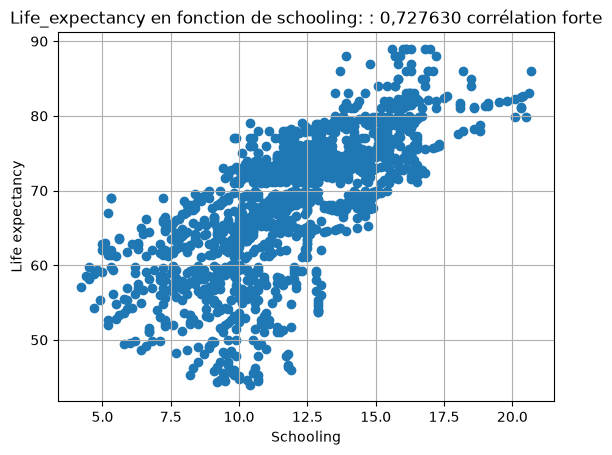

In [38]:
plt.scatter(df.Schooling, df.Life_expectancy)
plt.title("Life_expectancy en fonction de schooling: : 0,727630 corrélation forte")
plt.xlabel("Schooling")
plt.ylabel("Life expectancy")
plt.grid(True)
plt.show()

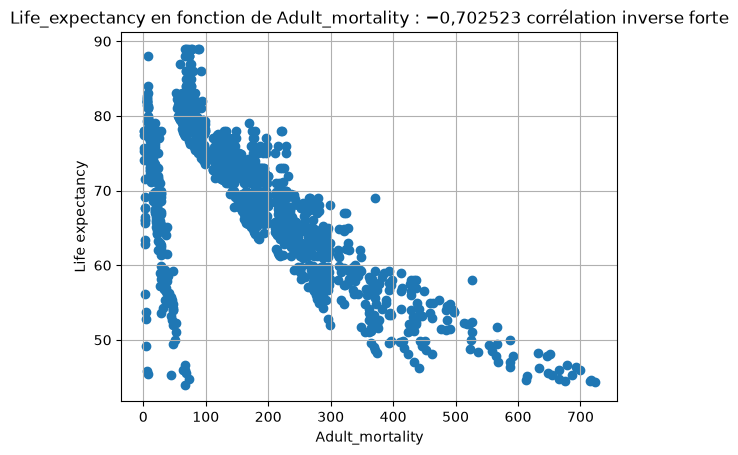

In [39]:
plt.scatter(df.Adult_mortality, df.Life_expectancy)
plt.title("Life_expectancy en fonction de Adult_mortality : −0,702523 corrélation inverse forte")
plt.xlabel("Adult_mortality")
plt.ylabel("Life expectancy")
plt.grid(True)
plt.show()

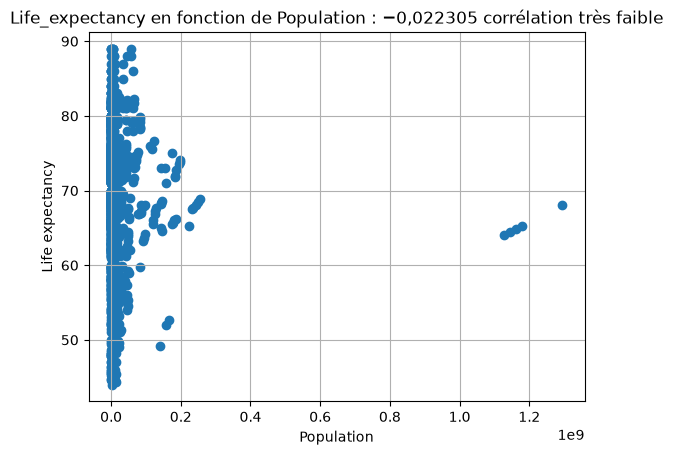

In [40]:
plt.scatter(df.Population, df.Life_expectancy)
plt.title("Life_expectancy en fonction de Population : −0,022305 corrélation très faible")
plt.xlabel("Population")
plt.ylabel("Life expectancy")
plt.grid(True)
plt.show()

Schooling (corr = 0,728 forte corrélation positive): Le nuage de points est globalement croissant. lorsque le niveau de scolarisation augmente, l'espérance de vie a tendance à augmenter. Schooling semble donc être un bon candidat pour prédire l'espérance de vie.

Adult mortality (corr = -0,703 forte corrélation négative): Lorsque la mortalité adulte augmente, l'espérance de vie a tendance à diminuer. Même si la corrélation est négative, sa valeur absolue est élevée, donc Adult_mortality peut également être un bon prédicteur.

Population (corr quasi nulle): Le nuage de points ne montre pas de tendance linéaire claire entre la population et l'espérance de vie. Population semble donc être un mauvais prédicteur de l'espérance de vie.

## Checkpoint : 1 
Call your teacher to validate the parts 1 and 2

## STEP 3: Simple Linear Regression

In [41]:
import numpy as np

**TO CODE 3.1**

Select the Life Expectancy and the Income composition of resources of Belarus, Madagascar, India and Lithuania. This new Data Frame will be called df_study

In [42]:
df_study = df[
    (df.Country == "Belarus") |
    (df.Country == "Madagascar") |
    (df.Country == "India") |
    (df.Country == "Lithuania")
][["Life_expectancy", "Income_composition_of_resources"]]

print(df_study)

      Life_expectancy  Income_composition_of_resources
225              72.0                            0.796
226              71.7                            0.796
227              71.9                            0.793
228              72.0                            0.787
229              73.0                            0.780
230              70.0                            0.771
231              70.0                            0.755
232              69.8                            0.739
233              68.9                            0.723
234              68.1                            0.713
235              68.2                            0.703
236              67.7                            0.695
237              67.2                            0.687
238              67.7                            0.681
239              68.0                            0.675
1187             68.0                            0.607
1188             67.6                            0.599
1189      

**TO CODE 3.2**

Implement a simple least square function and apply it on the previous selected data.

In [43]:
def least_square(x, y):
    a = np.sum((x - np.mean(x)) * (y - np.mean(y))) / np.sum((x - np.mean(x))**2)
    b = np.mean(y) - a * np.mean(x)
    return a, b

In [44]:
x = df_study.Income_composition_of_resources
y = df_study.Life_expectancy

a, b = least_square(x, y)

print("a =", a)
print("b =", b)

a = 28.5982261406769
b = 49.34763518833232


**TO CODE 3.3**

On the same figure, draw the line corresponding to your regression and the data points corresponding to df_study

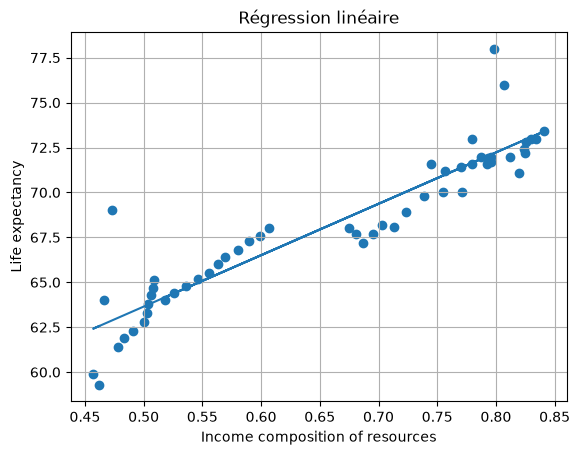

In [45]:
plt.scatter(x, y)
plt.plot(x, a*x + b)
plt.title("Régression linéaire")
plt.xlabel("Income composition of resources")
plt.ylabel("Life expectancy")
plt.grid(True)
plt.show()

## Checkpoint : 2
Call your teacher to validate the least square section

**TO CODE 3.4**

Now, implement a Gradient Descend function `def gradDescent(x, y, w, alpha, iters)` where `x` are
the covariates, `y` the target value, `w` the initial weights, `alpha` the learning rate and `iters` the number of gradient descent iterations. Your function should return all intermediary values of `w` that has been computed as a list.

As a gentle reminder, Gradient Descent is an optimization algorithm for finding a local minimum of a differentiable function. It is an iterative algorithm that aim to find the `w`  that minimizes our objective function. Since we aim to minimize the squared error, we aim to minimize the function : $L(y, \hat{y})=\sum\limits_{i=1}^n (y_i - w_1x_i-w_0)^2 $

Since previous function is convex, the derivative at each point indicate the **opposite** direction of the minimum. Thus, the idea is to update each weight by a small proportion of the opposite of this direction : 
$w_i^{t+1} = w_i^t - \alpha \frac{d(L(y, \hat{y}))}{d(w_i)}$

Be careful : here we have to update two weights, so we have to compute both derivative. Pay also attention on the fact that the derivative is computed according to $w_i$. Once you noticed that, calculating the derivative is pretty straightforward

In [46]:
def gradDescent(x, y, w, alpha, iters):
    L = []

    for i in range(iters):
        dw0 = -2 * np.sum(y - w[1]*x - w[0])    # dL/dw0
        dw1 = -2 * np.sum(x * (y - w[1]*x - w[0]))    # dL/dw1
        w[0] = w[0] - alpha * dw0
        w[1] = w[1] - alpha * dw1
        L.append(w.copy())
    return L

**TO CODE 3.5**

Compute the gradient descend on df_study for 1000 iterations with different values of `alpha`. You
may initialize `theta` with `theta_0 = 0` and `theta_1 = 1`

In [47]:
x = df_study.Income_composition_of_resources
y = df_study.Life_expectancy

for alpha in [0.00001, 0.0001, 0.001]:
    w = np.array([0.0, 1.0])
    L = gradDescent(x, y, w, alpha, 1000)
    
    print("alpha =", alpha, " -> w =", L[-1])

alpha = 1e-05  -> w = [37.02086821 25.69602931]
alpha = 0.0001  -> w = [47.15404024 31.87712772]
alpha = 0.001  -> w = [48.67855162 29.5983513 ]


**TO CODE 3.6**

On the same figure, plot the evolution of theta_0 through the iterations for each different values of
alpha you chose. Do the same thing for theta_1.

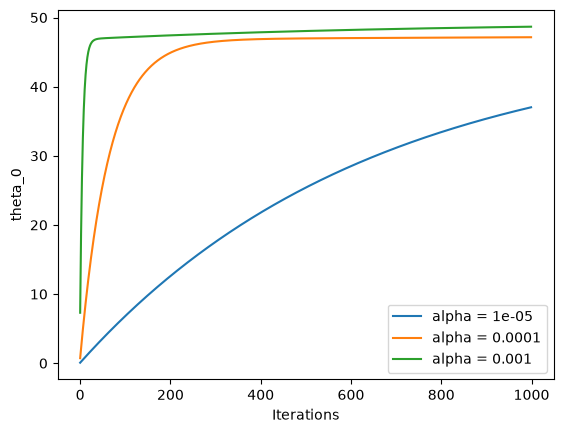

In [48]:
for alpha in [0.00001, 0.0001, 0.001]:
    w = np.array([0.0, 1.0])
    L = gradDescent(x, y, w, alpha, 1000)

    theta_0 = [w[0] for w in L]
    plt.plot(theta_0, label="alpha = " + str(alpha))

plt.xlabel("Iterations")
plt.ylabel("theta_0")
plt.legend()
plt.show()

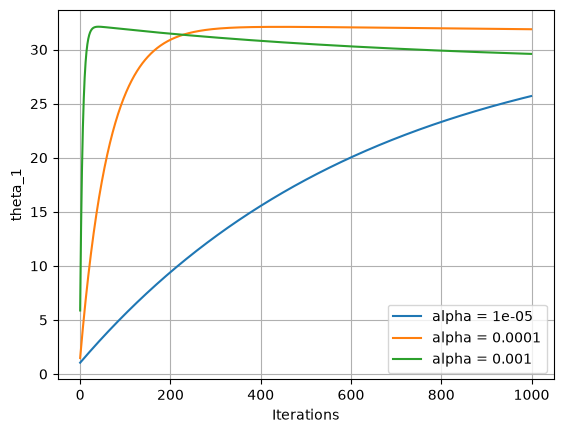

In [49]:
for alpha in [0.00001, 0.0001, 0.001]:
    w = np.array([0.0, 1.0])
    L = gradDescent(x, y, w, alpha, 1000)

    theta_1 = [w[1] for w in L]
    plt.plot(theta_1, label="alpha = " + str(alpha))

plt.xlabel("Iterations")
plt.ylabel("theta_1")
plt.legend()
plt.grid(True)
plt.show()

**Question 7**

Discuss on the role of alpha

Plus alpha est petit, plus on avance lentement vers le minimum mais plus il est grand, plus on avance vite. S'il est trop grand, on risque de dépasser le minimum et de ne jamais converger.

$R^2$ is the coefficient of determination useful to score a regression against the ground truth data.

This coefficient can be computed with a sklearn function:

```
sklearn.metrics.r2_score(y_true, y_pred, *, sample_weight=None, multioutput='uniform_average')
```

With:

**y_true** array-like of shape (n_samples,) or (n_samples, n_outputs)

Ground truth (correct) target values.

**y_pred** array-like of shape (n_samples,) or (n_samples, n_outputs)

Estimated target values.

**sample_weight** array-like of shape (n_samples,), default=None

Sample weights.

**multioutput** {‘raw_values’, ‘uniform_average’, ‘variance_weighted’}, array-like of shape (n_outputs,) or None, default=’uniform_average’

Defines aggregating of multiple output scores. Array-like value defines weights used to average scores. Default is “uniform_average”.

- ‘raw_values’: Returns a full set of scores in case of multioutput input.

- ‘uniform_average’: Scores of all outputs are averaged with uniform weight.

- ‘variance_weighted’: Scores of all outputs are averaged, weighted by the variances of each individual output.


In [56]:
from sklearn.metrics import r2_score

**TO CODE 3.7**

Compute $R^2$ on the regression with df_study

In [57]:
from sklearn.metrics import r2_score

x = df_study.Income_composition_of_resources
y = df_study.Life_expectancy

y_pred = a * x + b

R2 = r2_score(y, y_pred)

print("R² =", R2)

R² = 0.846632270152281


In [58]:
y = df_study.Life_expectancy
y_pred = a * x + b
R2 = 1 - sum((y - y_pred)**2) / sum((y - np.mean(y))**2)

print("R² =", R2)

R² = 0.846632270152281


Par les 2 méthode, on retrouve R² = 0,847 proche de 1.

**QUESTION 8**

Is linear regression suited between the two selected variables?

On a R² = 0,847 proche de 1. Notre régression linéaire explique environ 85 % des variations de l’espérance de vie dans les données étudiées. Le modèle représente donc plutôt bien les données.

**QUESTION 9**

If not, what would be the relevant regression between these two variables?

On a calculé R² avec deux variables très corrélés, donc R²=0.85 est très proche de 1.
Dans le cas ou l'on a R² proche de 0, on peut soit prendre une variable plus corélé à la deuxième, soit utiliser une autre méthode de régression comme LOOCV.

## Checkpoint : 3
Call your teacher to validate the rest of section 3

## STEP 4: Diagnostic visualization

**TO CODE 4.1**

Compute the residuals and plot the residuals vs fitted values.

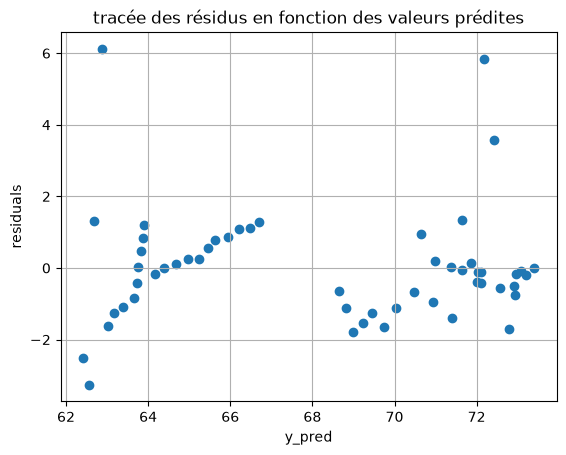

In [61]:
residuals= y - y_pred

plt.scatter(y_pred, residuals)
plt.title("tracée des résidus en fonction des valeurs prédites")
plt.xlabel("y_pred")
plt.ylabel("residuals")
plt.grid(True)
plt.show()

**Question 10**

What can you conclude about this plot ?


Les résidus sont globalement autour de 0, mais on remarque certaines valeurs assez éloignées de 0. La régression linéaire fonctionne donc plutôt bien, mais elle ne représente pas parfaitement les données.
Le R² proche de 1 montre que la régression est plutôt bonne et intéressante, mais l’étude des résidus montre que le modèle linéaire n’est pas parfait.

**TO CODE 4.2**

Also compute the Scale Location plot


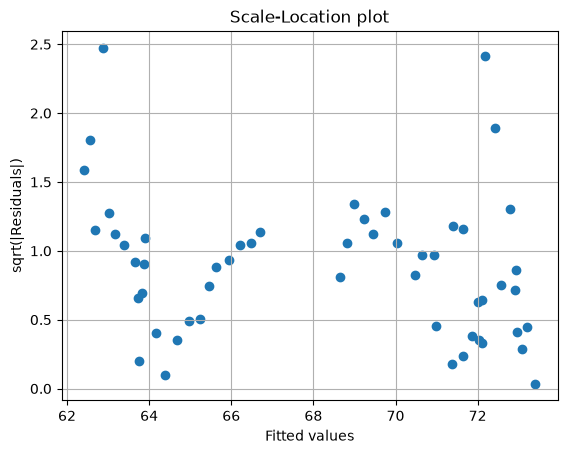

In [62]:
scale_location = np.sqrt(np.abs(residuals))

plt.scatter(y_pred, scale_location)

plt.xlabel("Fitted values")
plt.ylabel("sqrt(|Residuals|)")
plt.grid(True)
plt.title("Scale-Location plot")

plt.show()

**Question 11**

What can you conclude about this plot ?


On remarque que les points sont réparti de façon irrégulière. La dispersion des erreurs varie selon les valeurs prédites. Il y a également quelques points qui sont plus haut comme les 2 3 points au début et à la fin. Cela montre que la régression linéaire représente assez bien les données, mais reste imparfaite.

**TO CODE 4.3**

Compute now the Cook's distance for our data. You can compute it by yourself or use any library you can find.


$D_i = \frac{\sum_{j=1}^{n} \left(\hat{y}_j - \hat{y}_{j(i)}\right)^2}{p \times \text{MSE}}$

In [66]:
import statsmodels.api as sm
x = df_study.Income_composition_of_resources
y = df_study.Life_expectancy

# 2. Ajout d'une constante pour l'intercept
X = sm.add_constant(x)

# 3. Ajustement du modèle de régression linéaire
model = sm.OLS(y, X).fit()

# 4. Calcul de la distance de Cook
influence = model.get_influence()
cooks_distances, p_values = influence.cooks_distance

# 5. Affichage des distances pour chaque observation
for i, distance in enumerate(cooks_distances):
    print(f"Observation {i} : Distance de Cook = {distance:.4f}")


# aider par le site: https://www.statology.org/cooks-distance-python/

Observation 0 : Distance de Cook = 0.0001
Observation 1 : Distance de Cook = 0.0013
Observation 2 : Distance de Cook = 0.0001
Observation 3 : Distance de Cook = 0.0001
Observation 4 : Distance de Cook = 0.0120
Observation 5 : Distance de Cook = 0.0120
Observation 6 : Distance de Cook = 0.0048
Observation 7 : Distance de Cook = 0.0023
Observation 8 : Distance de Cook = 0.0055
Observation 9 : Distance de Cook = 0.0111
Observation 10 : Distance de Cook = 0.0062
Observation 11 : Distance de Cook = 0.0088
Observation 12 : Distance de Cook = 0.0119
Observation 13 : Distance de Cook = 0.0046
Observation 14 : Distance de Cook = 0.0015
Observation 15 : Distance de Cook = 0.0070
Observation 16 : Distance de Cook = 0.0055
Observation 17 : Distance de Cook = 0.0054
Observation 18 : Distance de Cook = 0.0037
Observation 19 : Distance de Cook = 0.0033
Observation 20 : Distance de Cook = 0.0017
Observation 21 : Distance de Cook = 0.0004
Observation 22 : Distance de Cook = 0.0004
Observation 23 : Dist

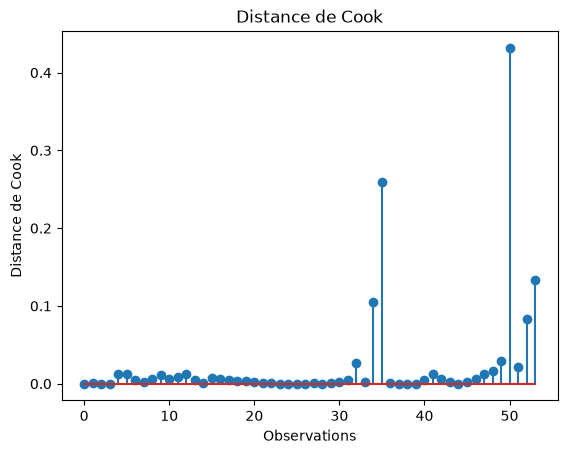

In [69]:
plt.stem(cooks_distances)
plt.xlabel("Observations")
plt.ylabel("Distance de Cook")
plt.title("Distance de Cook")
plt.show()

# Checkpoint : 1

Call your teacher to validate the parts 1 and 2

What can you conclude about this plot ?

On observe instantanément les points (données) qui pose problème:
Point 35 : 0,260
Point 50 : 0,432, la donnée la plus influente
Point 53 : 0,134
Point 34 : 0,105


TO DO 4.1

We are now adding multiple variable in our regression problem. Run the following cell in order to add multiple variables to your model :

In [72]:

from sklearn.preprocessing import scale
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

df_study = df[(df.Country == "Belarus") | (df.Country == "Madagascar") | (df.Country == "India") | (df.Country == "Lithuania")]
y = df_study.Life_expectancy
X = df_study[['Adult_mortality', 'Alcohol', 'Total_expenditure', 'Income_composition_of_resources', 'Schooling', "HIV_AIDS"]].to_numpy(dtype='float64')



Ici, on voit directement les donnés avec une grande distances de Cook. Elles sont majoritairement à la fin.

**Question 12**

What can you conclude about this plot ?


On observe instantanément les points (données) qui pose problème:
Point 35 : 0,260
Point 50 : 0,432, la donnée la plus influente
Point 53 : 0,134
Point 34 : 0,105

**TO DO 4.1** 

We are now adding multiple variable in our regression problem. Run the following cell in order to add multiple variables to your model : 

In [ ]:
from sklearn.preprocessing import scale
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

df_study = df[(df.Country == "Belarus") | (df.Country == "Madagascar") | (df.Country == "India") | (df.Country == "Lithuania")]
y = df_study.Life_expectancy
X = df_study[['Adult_mortality', 'Alcohol', 'Total_expenditure', 'Income_composition_of_resources', 'Schooling', "HIV_AIDS"]].to_numpy(dtype='float64')

**TO CODE 4.4**

Dealing with too many variables can sometimes be counter-productive and it can be more interesting to remove some features. One way to evaluate the importance of each variable is to compute the f_test whose function is named f_regression in sklearn. 

In [ ]:
from sklearn.feature_selection import f_regression

f_test, N= f_regression(x, y)

plt.plot(f_test, p_values)
plt.xlabel("f_test")
plt.ylabel("p_values")
plt.grid(True)
plt.show()


**QUESTION 13**

According to the f_test, rank each variable from the least to the most promising. Compare it with the correlation of your subset.

## Checkpoint : 4
Call your teacher to validate the section 4. Congrats, you finished the first TP !